In [1]:
import torch
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yf
from newsapi import NewsApiClient
from fredapi import Fred
import cvxpy as cp
import requests
import time
import os
import json
import scipy.stats as stats

In [2]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
finbert = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert", device_map="auto")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [3]:
fred = Fred(api_key='key')

In [4]:
today = dt.date.today()
end_date = "2025-12-31"
###(today - dt.timedelta(days=1)).strftime("%Y-%m-%d")
start_date = "2025-01-01"
###(today - dt.timedelta(days=180)).strftime("%Y-%m-%d")
start_stock_date = "2024-01-01"
###(today - dt.timedelta(days=365)).strftime("%Y-%m-%d")
end_stock_date = end_date

tickers = [
     'nvda', 'aapl', 'msft', 'amzn', 'googl',
    'avgo', 'meta', 'mu', 'wmt', 'tsla',
    'nflx', 'cost', 'adbe', 'pep', 'tmus',
    'csco', 'cmcsa', 'intc', 'qcom', 'intu'
]

def newspull(tickers, start_date, end_date):
    datatable = {}

    start_date_api = start_date.replace("-", "") + "T0000"
    end_date_api = end_date.replace("-", "") + "T2359"

    for i in tickers:

        filename = f"news_cache/{i}_{start_date}_{end_date}.json"
        if os.path.exists(filename):

            print(f"{i}: loading from local file")

            with open(filename, "r") as f:
                data = json.load(f)
        else:
            params = {
                "function": "NEWS_SENTIMENT",
                "tickers": i,
                "time_from": start_date_api,
                "time_to": end_date_api,
                "sort": "RELEVANCE",
                "limit": 1000,
                "apikey": "key",
            }
            print(f"{i}: downloading from Alpha Vantage")

            r = requests.get("https://www.alphavantage.co/query",params=params)
            data = r.json()

            if "feed" not in data:
                print(f"{i}: {data}")
            with open(filename, "w") as f:
                json.dump(data, f)

            time.sleep(3.2)

        articles = data.get("feed", [])

        if not articles:
            print(f"No articles found for: {i}")
            datatable[i] = pd.Series(dtype="object")
            os.remove(filename)
            continue

        temp = pd.DataFrame(articles)
        temp["publishedAt"] = pd.to_datetime(temp["time_published"], format="%Y%m%dT%H%M%S")
        temp["index"] = temp.groupby("publishedAt").cumcount()
        temp.index = pd.MultiIndex.from_arrays(
            [temp["publishedAt"], temp["index"]],
            names=["date", "index"]
        )
        datatable[i] = temp["summary"]
    return pd.DataFrame(datatable)

def pull(ticker,start,end):
    stock = yf.Ticker(ticker)
    daily = stock.history(start=start, end=end, interval = "1d")
    daily = daily[['Close']]
    daily = daily.dropna()
    daily['Return'] = daily['Close'].pct_change()
    daily=daily.drop('Close', axis=1)
    daily.index = pd.to_datetime(daily.index).tz_localize(None)
    return daily

def sentiment(datatable):
    scores = {}
    for s in list(datatable.columns):
        pos=0
        neg=0
        count=0
        for i in datatable[s]:
            if not pd.isna(i):
                text = i
                inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True)
                inputs = {k: v.to(finbert.device) for k, v in inputs.items()}
                
                finbert.eval()
                with torch.no_grad():
                    outputs = finbert(**inputs)
                    probs = torch.softmax(outputs.logits, dim=-1)
                pos += 1*probs[0,0].item()
                neg += 1*probs[0,1].item()
                count+=1
        sentiment_score = (pos - neg)/count if count > 0 else None
        scores[s]=sentiment_score
    return scores

print("done")

done


In [5]:
rets = {}
rets = pd.DataFrame(rets)
for q in tickers:
    rets[q] = pull(q,start_stock_date,end_stock_date)
rets = rets.dropna()
ten_yr_bonds = fred.get_series('DGS10') 
print("done")
rets.head()

done


,nvda,aapl,msft,amzn,googl,avgo,meta,mu,wmt,tsla,nflx,cost,adbe,pep,tmus,csco,cmcsa,intc,qcom,intu
Date,,,,,,,,,,,,,,,,,,,,
2024-01-03,-0.012436,-0.007488,-0.000728,-0.009738,0.005428,-0.024692,-0.005256,-0.000971,0.000063,-0.040134,0.003757,-0.009160,-0.014274,0.000232,0.001050,0.007781,-0.008244,-0.015690,-0.018754,-0.020902
2024-01-04,0.009018,-0.012700,-0.007178,-0.026268,-0.018212,-0.009040,0.007693,0.005470,-0.009667,-0.002181,0.009378,0.005677,-0.008290,-0.008558,0.001357,-0.008513,-0.015701,-0.003826,-0.010393,-0.007308
2024-01-05,0.022897,-0.004013,-0.000516,0.004634,-0.004839,0.000257,0.013914,0.008947,-0.006656,-0.001849,-0.001285,0.011815,-0.004321,-0.014755,0.006593,0.000200,0.009618,0.000427,0.004112,0.003749
2024-01-08,0.064281,0.024175,0.018872,0.026577,0.022913,0.024369,0.019065,0.017975,0.009827,0.012464,0.023141,0.008658,0.028250,0.001006,0.000245,0.007387,0.016032,0.033270,0.016822,0.015890
2024-01-09,0.016975,-0.002263,0.002936,0.015225,0.015197,0.007108,-0.003429,-0.019070,0.006698,-0.022832,-0.006061,0.008297,0.009732,-0.011472,-0.001285,-0.010900,-0.010290,-0.008256,0.006186,0.012888


In [6]:
news_df = newspull(tickers, start_date, end_date)
print("done")

nvda: loading from local file
aapl: loading from local file
msft: loading from local file
amzn: loading from local file
googl: loading from local file
avgo: loading from local file
meta: loading from local file
mu: loading from local file
wmt: loading from local file
tsla: loading from local file
nflx: loading from local file
cost: loading from local file
adbe: loading from local file
pep: loading from local file
tmus: loading from local file
csco: loading from local file
cmcsa: loading from local file
intc: loading from local file
qcom: loading from local file
intu: loading from local file
done


In [37]:
dates = (news_df.index.get_level_values(0).unique().normalize() + pd.Timedelta(hours=16)).unique()

def sentimentoptim(benchtick, dates, sentiment_wgt, risk_aversion, mean_var):
    benchpull = pull(benchtick,start_stock_date,end_stock_date)
    portfolio_value=1
    bench_value=1
    portfolio={}
    portfolio = pd.DataFrame(portfolio)
    portfolio.loc[start_date,'value'] = portfolio_value
    benchmark={}
    benchmark = pd.DataFrame(benchmark)
    benchmark.loc[start_date,'value'] = bench_value
    
    for d in dates:
        dts = pd.Timestamp(d).normalize()
        if dts not in rets.index:
            print("skip", d)
            continue 
        if not ((news_df.index.get_level_values(0) >= d - dt.timedelta(hours = 24)) & (news_df.index.get_level_values(0) <= d)).any():
            print("skip", d)
            continue
        #checks if its a monday, and then uses sunday, saturday, and friday for mondays
        if d.isoweekday() == 1:
            daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=24))]
            scores0 = sentiment(daily_news)
            scores0 = pd.DataFrame.from_dict(scores0, orient='index', columns=['sentiment'])
            scores0 = scores0.dropna()
            scores1 = pd.DataFrame(columns=['sentiment'])
            if ((news_df.index.get_level_values(0) >= d - dt.timedelta(hours = 48)) & (news_df.index.get_level_values(0) <= d)).any():
                daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=48))]
                scores1 = sentiment(daily_news)
                scores1 = pd.DataFrame.from_dict(scores1, orient='index', columns=['sentiment'])
                scores1 = scores1.dropna()
            scores2 = pd.DataFrame(columns=['sentiment'])
            if ((news_df.index.get_level_values(0) >= d - dt.timedelta(hours = 72)) & (news_df.index.get_level_values(0) <= d)).any():
                daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=72))]
                scores2 = sentiment(daily_news)
                scores2 = pd.DataFrame.from_dict(scores2, orient='index', columns=['sentiment'])
                scores2 = scores2.dropna()
            combined = pd.concat([scores0, scores1, scores2])
            scores = combined.groupby(combined.index).mean()
            scores = scores.sort_values(by='sentiment', ascending=False)
        else:
            daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=24))]
            scores = sentiment(daily_news)
            scores = pd.DataFrame.from_dict(scores, orient='index', columns=['sentiment'])
            scores = scores.dropna()
            scores = scores.sort_values(by='sentiment', ascending=False)
##neg
        if d.isoweekday() == 1:
            daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=24))]
            scoresneg0 = sentimentneg(daily_news)
            scoresneg0 = pd.DataFrame.from_dict(scores0, orient='index', columns=['sentiment'])
            scoresneg0 = scoresneg0.dropna()
            scoresneg1 = pd.DataFrame(columns=['sentiment'])
            if ((news_df.index.get_level_values(0) >= d - dt.timedelta(hours = 48)) & (news_df.index.get_level_values(0) <= d)).any():
                daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=48))]
                scoresneg1 = sentimentneg(daily_news)
                scoresneg1 = pd.DataFrame.from_dict(scores1, orient='index', columns=['sentiment'])
                scoresneg1 = scoresneg1.dropna()
            scoresneg2 = pd.DataFrame(columns=['sentiment'])
            if ((news_df.index.get_level_values(0) >= d - dt.timedelta(hours = 72)) & (news_df.index.get_level_values(0) <= d)).any():
                daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=72))]
                scoresneg2 = sentimentneg(daily_news)
                scoresneg2 = pd.DataFrame.from_dict(scores2, orient='index', columns=['sentiment'])
                scoresneg2 = scoresneg2.dropna()
            combinedneg = pd.concat([scoresneg0, scoresneg1, scoresneg2])
            scoresneg = combinedneg.groupby(combined.index).mean()
            scoresneg = scoresneg.sort_values(by='sentiment', ascending=False)
        else:
            daily_news = news_df.loc[(news_df.index.get_level_values(0) < d) & (news_df.index.get_level_values(0) > d-dt.timedelta(hours=24))]
            scoresneg = sentimentneg(daily_news)
            scoresneg = pd.DataFrame.from_dict(scoresneg, orient='index', columns=['sentiment'])
            scoresneg = scoresneg.dropna()
            scoresneg = scoresneg.sort_values(by='sentiment', ascending=False)
        
        todays_tickers = scores.index.tolist()
        local_rets = rets[todays_tickers][rets.index <= dts].tail(90)
    
        current_bonds = ten_yr_bonds[ten_yr_bonds.index <= dts]
        risk_free_rate_annual = (current_bonds.dropna().iloc[-1])/100
        rf_daily = risk_free_rate_annual/252
        scores['mean'] = local_rets.rolling(window=30).mean().iloc[-1]
        scores['volatility'] = local_rets.rolling(window=30).std().iloc[-1]
        scores['sharpe'] = ((scores['mean']-rf_daily)/scores['volatility'])*np.sqrt(252)
    
        cov = local_rets.cov().values
    
        scores = scores.dropna()
        scoresneg = scoresneg.dropna()
    
        n = len(scores)
        daily_ret = 0
        position = (rets.index.get_loc(dts))+1
        if position >= len(rets.index):
            print("skip", d)
            continue
        if n < 2:
            daily_ret += rets.loc[rets.index[position],todays_tickers[0]]
            # this makes it so if only one stock has news signal/sentiment it goes all in on it for that day
            daily_bench = benchpull['Return'].asof(rets.index[position])
            portfolio_value *= (1 + daily_ret)
            bench_value *= (1 + daily_bench)
            portfolio.loc[d,'value'] = portfolio_value
            benchmark.loc[d,'value'] = bench_value
            continue
        wgts = cp.Variable(n)
        
        mu = scores['mean'].values 
        if mu.std() == 0:
            daily_ret = benchpull['Return'].asof(rets.index[position])
            # this makes it so if the days you would have to skip because math doesn't work out, you just invest into the bench
            daily_bench = benchpull['Return'].asof(rets.index[position])
            portfolio_value *= (1 + daily_ret)
            bench_value *= (1 + daily_bench)
            portfolio.loc[d,'value'] = portfolio_value
            benchmark.loc[d,'value'] = bench_value
            print("bench", d)
            continue
        mu = (mu - mu.mean()) / mu.std()
        
        sentiment_scores = scores['sentiment'].values
        print(sentiment_scores)
        if sentiment_scores.std() == 0:
            daily_ret = benchpull['Return'].asof(rets.index[position])
            # this makes it so if the days you would have to skip because math doesn't work out, you just invest into the bench
            daily_bench = benchpull['Return'].asof(rets.index[position])
            portfolio_value *= (1 + daily_ret)
            bench_value *= (1 + daily_bench)
            portfolio.loc[d,'value'] = portfolio_value
            benchmark.loc[d,'value'] = bench_value
            print("bench", d)
            continue
        sentiment_scores = (sentiment_scores - sentiment_scores.mean()) / sentiment_scores.std()
            
        portfolio_ret = mu @ wgts
        portfolio_risk = cp.quad_form(wgts, cov)
        portfolio_sentiment = sentiment_scores @ wgts
                
        objective = cp.Maximize(mean_var*(portfolio_ret - (100*risk_aversion * portfolio_risk)) + (sentiment_wgt * portfolio_sentiment))
        constraints = [cp.sum(wgts) == 0, min(-0.25, -1/n) <= wgts, wgts <= max(0.25, 1/n)]
        
        problem = cp.Problem(objective, constraints)
        problem.solve()

        clean_wgts = wgts.value
        clean_wgts = np.where(clean_wgts < 1e-3, 0, clean_wgts)
        if np.isclose((np.abs(clean_wgts)).sum(), 0):
            clean_wgts = np.zeros_like(clean_wgts)
        else:
            clean_wgts = clean_wgts / (np.abs(clean_wgts)).sum()
        print(d)
        print(clean_wgts)
        # can add print(clean_wgts) to see weighting
        for r  in range(len(todays_tickers)):
            daily_ret += rets.loc[rets.index[position],todays_tickers[r]]*clean_wgts[r]
            daily_bench = benchpull['Return'].asof(rets.index[position])
        portfolio_value *= (1 + daily_ret)
        bench_value *= (1 + daily_bench)
        portfolio.loc[d,'value'] = portfolio_value
        benchmark.loc[d,'value'] = bench_value
        
    return benchmark, portfolio


In [20]:
def test(portfolio, benchmark):
    graph = portfolio["value"].plot(label='portfolio', color='blue')
    benchmark["value"].plot(ax=graph, label='benchmark', color='red')

    test={}
    test = pd.DataFrame(test)

    trading_days = len(portfolio)

    portfolio_cumret = (portfolio['value'].iloc[-1] - portfolio['value'].iloc[0])/portfolio['value'].iloc[0]
    bench_cumret = (benchmark['value'].iloc[-1] - benchmark['value'].iloc[0])/benchmark['value'].iloc[0]
    
    cummax_p = portfolio['value'].cummax()
    drawdown_p = (portfolio['value'] - cummax_p) / cummax_p
    max_drawdown_p = drawdown_p.min()

    cummax_b = benchmark['value'].cummax()
    drawdown_b = (benchmark['value'] - cummax_b) / cummax_b
    max_drawdown_b = drawdown_b.min()
    
    portfolio['Return'] = portfolio['value'].pct_change()
    
    benchmark['Return'] = benchmark['value'].pct_change()

    portfolio_s = pd.Series(portfolio['Return'])
    benchmark_s = pd.Series(benchmark['Return'])
    
    test.loc['portfolio','meanret'] = portfolio['Return'].mean()
    test.loc['portfolio','volatility'] = portfolio['Return'].std()
    test.loc['portfolio','sharpe'] = ((test.loc['portfolio','meanret'])/test.loc['portfolio','volatility'])*np.sqrt(252)
    test.loc['portfolio','cumret'] = portfolio_cumret
    test.loc['portfolio','annualret'] = ((1+portfolio_cumret) ** (252/trading_days))-1
    test.loc['portfolio','correlation'] = portfolio_s.corr(benchmark_s)

    #calculates rolling beta
    merged = pd.merge(benchmark, portfolio, how='inner', left_index=True, right_index=True, suffixes=('_x', '_y'))
    merged=merged.dropna()
    beta, daily_alpha, r_value, p_value, std_err = stats.linregress(merged['Return_x'], merged['Return_y'])

    test.loc['portfolio','beta'] = beta
    test.loc['portfolio','dailyalpha'] = daily_alpha

    test.loc['portfolio','maxdrawdown'] = max_drawdown_p

    #calculates alpha t-stat
    N = len(merged)
    residuals = merged['Return_y'] - (daily_alpha + (beta * merged['Return_x']))
    SSE = (residuals**2).sum()
    residual_var = SSE/(N - 2)
    bench_std = benchmark['Return'].std()
    bench_meanret = benchmark['Return'].mean()
    SE_alpha = np.sqrt(residual_var * ((1/N) + ((bench_meanret ** 2)/((bench_std ** 2) * (N - 1)))))
    t_stat = daily_alpha/SE_alpha
    p_val = stats.t.sf(np.abs(t_stat), df= N - 2)*2

    test.loc['portfolio','alpha_t_stat'] = t_stat
    test.loc['portfolio','alpha_p_val'] = p_val

    
    test.loc['benchmark','meanret'] = bench_meanret
    test.loc['benchmark','volatility'] = bench_std
    test.loc['benchmark','sharpe'] = ((test.loc['benchmark','meanret'])/test.loc['benchmark','volatility'])*np.sqrt(252)
    test.loc['benchmark','cumret'] = bench_cumret
    test.loc['benchmark','annualret'] = ((1+bench_cumret) ** (252/trading_days))-1
    test.loc['benchmark','correlation'] = benchmark_s.corr(portfolio_s)
    test.loc['benchmark','beta'] = 1
    test.loc['benchmark','dailyalpha'] = 0
    test.loc['benchmark','maxdrawdown'] = max_drawdown_b

    return test

In [38]:
b, p = sentimentoptim("TOPT", dates, 1, 1, 1)
#equal sentiment/risk aversion ratio -- default

[ 0.7570242 -0.9194154]
2025-01-02 16:00:00
[1. 0.]
skip 2025-01-04 16:00:00
skip 2025-01-05 16:00:00
[ 0.39680795  0.11233338 -0.41452172]
2025-01-06 16:00:00
[0. 1. 0.]
[0.57357059 0.4931614 ]
2025-01-07 16:00:00
[1. 0.]
[ 0.93836473  0.35594089 -0.01047101]
2025-01-08 16:00:00
[1. 0. 0.]
skip 2025-01-09 16:00:00
[0.85968331 0.59808515]
2025-01-13 16:00:00
[0. 0.]
[0.31466729 0.20270268]
2025-01-14 16:00:00
[1. 0.]
[ 7.86652691e-01  2.85628514e-01  3.29885632e-04 -3.87532730e-02]
2025-01-15 16:00:00
[0.5 0.5 0.  0. ]
[0.93233151 0.7475421  0.51455606 0.38905021]
2025-01-16 16:00:00
[0.49999577 0.50000423 0.         0.        ]
skip 2025-01-20 16:00:00
[0.86011346 0.24361644]
2025-01-21 16:00:00
[1. 0.]
[9.30444745e-01 8.60988680e-01 1.63941160e-01 6.18427526e-04]
2025-01-22 16:00:00
[0.5 0.5 0.  0. ]
[0.93795657 0.84137354 0.695309   0.17181507]
2025-01-23 16:00:00
[0.5 0.5 0.  0. ]
skip 2025-01-25 16:00:00
[0.59836924 0.28437184]
2025-01-27 16:00:00
[1. 0.]
skip 2025-01-28 16:00:00


In [21]:
b2, p2 = sentimentoptim("TOPT", dates, -1, 1, 1)
#equal negative sentiment/risk aversion ratio -- inverse default

2025-01-02 16:00:00
skip 2025-01-04 16:00:00
skip 2025-01-05 16:00:00
2025-01-06 16:00:00
2025-01-07 16:00:00
2025-01-08 16:00:00
skip 2025-01-09 16:00:00
2025-01-13 16:00:00
2025-01-14 16:00:00
2025-01-15 16:00:00
2025-01-16 16:00:00
skip 2025-01-20 16:00:00
2025-01-21 16:00:00
2025-01-22 16:00:00
2025-01-23 16:00:00
skip 2025-01-25 16:00:00
2025-01-27 16:00:00
skip 2025-01-28 16:00:00
2025-01-29 16:00:00
2025-01-30 16:00:00
2025-01-31 16:00:00
skip 2025-02-01 16:00:00
skip 2025-02-02 16:00:00
2025-02-03 16:00:00
2025-02-04 16:00:00
2025-02-05 16:00:00
2025-02-06 16:00:00
2025-02-07 16:00:00
2025-02-10 16:00:00
2025-02-11 16:00:00
2025-02-12 16:00:00
2025-02-13 16:00:00
2025-02-14 16:00:00
skip 2025-02-15 16:00:00
2025-02-18 16:00:00
2025-02-19 16:00:00
2025-02-20 16:00:00
2025-02-21 16:00:00
2025-02-24 16:00:00
2025-02-25 16:00:00
2025-02-26 16:00:00
2025-02-27 16:00:00
2025-02-28 16:00:00
skip 2025-03-01 16:00:00
skip 2025-03-02 16:00:00
2025-03-03 16:00:00
2025-03-04 16:00:00
2025-

In [27]:
b3, p3 = sentimentoptim("TOPT", dates, 1, 0, 0)
#sentiment only

2025-01-02 16:00:00
skip 2025-01-04 16:00:00
skip 2025-01-05 16:00:00
2025-01-06 16:00:00
2025-01-07 16:00:00
2025-01-08 16:00:00
skip 2025-01-09 16:00:00
2025-01-13 16:00:00
2025-01-14 16:00:00
2025-01-15 16:00:00
2025-01-16 16:00:00
skip 2025-01-20 16:00:00
2025-01-21 16:00:00
2025-01-22 16:00:00
2025-01-23 16:00:00
skip 2025-01-25 16:00:00
2025-01-27 16:00:00
skip 2025-01-28 16:00:00
2025-01-29 16:00:00
2025-01-30 16:00:00
2025-01-31 16:00:00
skip 2025-02-01 16:00:00
skip 2025-02-02 16:00:00
2025-02-03 16:00:00
2025-02-04 16:00:00
2025-02-05 16:00:00
2025-02-06 16:00:00
2025-02-07 16:00:00
2025-02-10 16:00:00
2025-02-11 16:00:00
2025-02-12 16:00:00
2025-02-13 16:00:00
2025-02-14 16:00:00
skip 2025-02-15 16:00:00
2025-02-18 16:00:00
2025-02-19 16:00:00
2025-02-20 16:00:00
2025-02-21 16:00:00
2025-02-24 16:00:00
2025-02-25 16:00:00
2025-02-26 16:00:00
2025-02-27 16:00:00
2025-02-28 16:00:00
skip 2025-03-01 16:00:00
skip 2025-03-02 16:00:00
2025-03-03 16:00:00
2025-03-04 16:00:00
2025-

            meanret  volatility    sharpe    cumret  annualret  correlation  \
portfolio  0.000972    0.018276  0.844533  0.217481   0.223339     0.506594   
benchmark  0.001020    0.013847  1.169822  0.254524   0.261481     0.506594   

               beta  dailyalpha  maxdrawdown  alpha_t_stat  alpha_p_val  
portfolio  0.668613     0.00029    -0.239543      0.286717     0.774574  
benchmark  1.000000     0.00000    -0.211564           NaN          NaN  


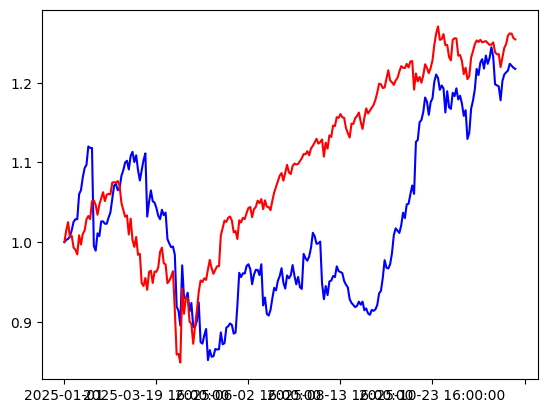

In [26]:
print(test(p,b))
#default/equal ratio

            meanret  volatility    sharpe    cumret  annualret  correlation  \
portfolio  0.000564    0.014227  0.629068  0.120045   0.123146     0.613932   
benchmark  0.001020    0.013847  1.169823  0.254524   0.261481     0.613932   

               beta  dailyalpha  maxdrawdown  alpha_t_stat  alpha_p_val  
portfolio  0.630762    -0.00008    -0.158538     -0.110796     0.911869  
benchmark  1.000000     0.00000    -0.211564           NaN          NaN  


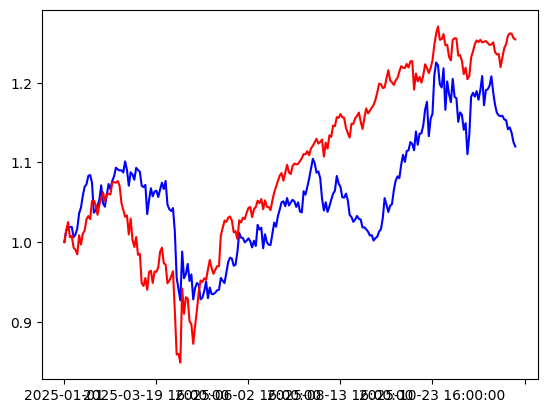

In [57]:
print(test(p2,b2))
#inverse

            meanret  volatility    sharpe    cumret  annualret  correlation  \
portfolio  0.000401    0.017502  0.363316  0.061972   0.063530     0.542158   
benchmark  0.001020    0.013847  1.169822  0.254524   0.261481     0.542158   

               beta  dailyalpha  maxdrawdown  alpha_t_stat  alpha_p_val  
portfolio  0.685264   -0.000299    -0.242899     -0.316387      0.75198  
benchmark  1.000000    0.000000    -0.211564           NaN          NaN  


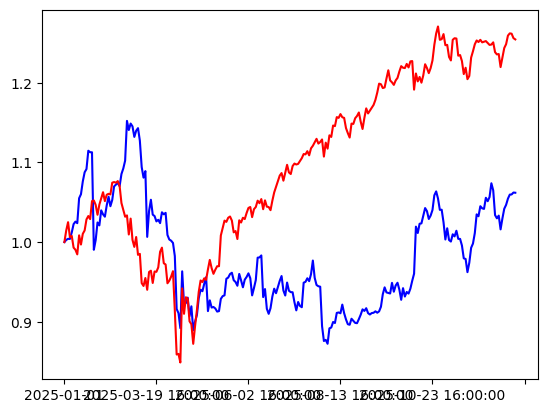

In [28]:
print(test(p3,b3))
#sentiment only